

 **Task 1 — Data Import & Setup**

#load the CSV with Pandas, inspect dtypes, convert the date column to datetime and use NumPy for basic array operations.



In [5]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

URL = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/main/social_media_engagement_5000.csv"
try:
    df = pd.read_csv(URL)                       # works in Colab
except Exception:
    df = pd.read_csv("social_media_engagement_5000.csv")   # fallback: file uploaded locally
print("Loaded shape:", df.shape)
df.head()

Loaded shape: (5000, 19)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [2]:
# Check data types
print(df.dtypes)

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


In [3]:
# Convert the date column. The format is day-month-year, so pass dayfirst/format explicitly
df["posted_at"] = pd.to_datetime(df["posted_at"], format="%d-%m-%Y")
print(df["posted_at"].dtype, "|", df["posted_at"].min().date(), "→", df["posted_at"].max().date())

datetime64[ns] | 2022-01-01 → 2023-12-31


In [4]:
# NumPy array operations on a numeric column
likes_arr = df["likes"].to_numpy()               # Pandas Series -> NumPy array
print("Array shape:", likes_arr.shape, "| dtype:", likes_arr.dtype)
print("np.nanmean  :", np.nanmean(likes_arr).round(2))
print("np.nanmedian:", np.nanmedian(likes_arr))
print("np.nanmax / np.nanmin:", np.nanmax(likes_arr), "/", np.nanmin(likes_arr))
print("Missing entries (np.isnan):", np.isnan(likes_arr).sum())

interactions = np.nan_to_num(df[["likes","comments","shares"]].to_numpy()).sum(axis=1)
print("First 5 total interactions:", interactions[:5])

Array shape: (5000,) | dtype: float64
np.nanmean  : 10107.04
np.nanmedian: 10105.5
np.nanmax / np.nanmin: 19998.0 / 10.0
Missing entries (np.isnan): 150
First 5 total interactions: [ 8522. 16163.  6161.  7482. 16717.]


**Task 2 — Data Cleaning**

2.1 Missing values

isnull() / isna() where data is missing. The strategy depends on the column type:

Numeric (age, likes, comments, shares) → fill with the median.

Categorical (gender, sentiment) → fill with the mode

In [7]:

missing = df.isnull().sum()
print(missing[missing > 0])
print("\nMissing % per column:")
print((df.isna().mean() * 100).round(2)[lambda s: s > 0])

age          150
gender       150
likes        150
comments     150
shares       150
sentiment    150
dtype: int64

Missing % per column:
age          3.0
gender       3.0
likes        3.0
comments     3.0
shares       3.0
sentiment    3.0
dtype: float64


In [8]:
df_clean = df.copy()

# Numeric -> median
for col in ["age", "likes", "comments", "shares"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Categorical -> mode for gender; sentiment is set to 'neutral' rather than guessing positive/negative
df_clean["gender"] = df_clean["gender"].fillna(df_clean["gender"].mode()[0])
df_clean["sentiment"] = df_clean["sentiment"].fillna("neutral")

print("Remaining missing values:", df_clean.isnull().sum().sum())

Remaining missing values: 0


**2.2 Duplicates**

In [9]:
print("Fully duplicated rows:", df_clean.duplicated().sum())
print("Duplicated post_id values:", df_clean["post_id"].duplicated().sum())

Fully duplicated rows: 0
Duplicated post_id values: 9


In [10]:
# Remove exact duplicate rows , then look at duplicate post_ids.
df_clean = df_clean.drop_duplicates()

# A post_id should be unique. Keep the first occurrence of each post.
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset="post_id", keep="first").reset_index(drop=True)
print(f"Rows: {before} -> {len(df_clean)}  (removed {before-len(df_clean)} repeated post_id rows)")

Rows: 5000 -> 4991  (removed 9 repeated post_id rows)


**2.3 Formatting: data types & standardising categories**

In [11]:
# Counts must be integers
for col in ["age", "likes", "comments", "shares"]:
    df_clean[col] = df_clean[col].astype(int)

# strip spaces + consistent case
for col in ["gender", "post_type", "post_category", "device_type", "sentiment"]:
    df_clean[col] = df_clean[col].astype(str).str.strip().str.lower()
df_clean["country"] = df_clean["country"].str.strip()
df_clean["gender"] = df_clean["gender"].replace({"m": "male", "f": "female"})  # guards against label variants

# is_verified is already bool
df_clean["is_verified"] = df_clean["is_verified"].astype(str).str.upper().map({"TRUE": True, "FALSE": False})

for col in ["gender", "post_type", "post_category", "device_type", "sentiment"]:
    print(col, "->", sorted(df_clean[col].unique()))

gender -> ['female', 'male', 'other']
post_type -> ['image', 'reel', 'text', 'video']
post_category -> ['education', 'fashion', 'fitness', 'food', 'lifestyle', 'music', 'tech', 'travel']
device_type -> ['desktop', 'mobile', 'tablet']
sentiment -> ['negative', 'neutral', 'positive']


**2.4 Unrealistic values**

Checks: negative counts, impossible ages, and engagement_rate > 1. Engagement rate = (likes + comments + shares) / impressions.



In [12]:
print("Negative likes/comments/shares:", (df_clean[["likes","comments","shares"]] < 0).sum().sum())
print("Age outside 13-100:", (~df_clean["age"].between(13, 100)).sum())

# Verify how engagement_rate was built
calc = (df_clean.likes + df_clean.comments + df_clean.shares) / df_clean.impression_count
print("Max |calculated - given| engagement_rate:", (calc - df_clean.engagement_rate).abs().max())

print("\nPosts with engagement_rate > 1 (100%):", (df_clean.engagement_rate > 1).sum())
print("Max engagement_rate:", df_clean.engagement_rate.max())

Negative likes/comments/shares: 0
Age outside 13-100: 0
Max |calculated - given| engagement_rate: 2.926997840401728

Posts with engagement_rate > 1 (100%): 601
Max engagement_rate: 191.5043478


In [13]:
# 1) Flag impossible rows so we can analyse with and without them
df_clean["is_anomaly"] = df_clean["engagement_rate"] > 1

# 2) Cap engagement_rate at 1.0 (100%) - the logical ceiling. Keep the original for transparency
df_clean["engagement_rate_raw"] = df_clean["engagement_rate"]
df_clean["engagement_rate"] = df_clean["engagement_rate"].clip(upper=1.0)

# 3) Winsorise (cap at 1st/99th percentile) likes, comments, shares so extremes cannot dominate
for col in ["likes", "comments", "shares"]:
    lo, hi = df_clean[col].quantile([0.01, 0.99])
    df_clean[col] = df_clean[col].clip(lo, hi).astype(int)

print("Anomalous rows flagged:", df_clean.is_anomaly.sum(), f"({df_clean.is_anomaly.mean():.1%})")
print("engagement_rate now ranges", df_clean.engagement_rate.min().round(4), "to", df_clean.engagement_rate.max())

Anomalous rows flagged: 601 (12.0%)


AttributeError: 'float' object has no attribute 'round'

**2.5 Feature cleaning — hashtag count & sentiment labels**

In [14]:
# hashtags look like '#foodie #travel #love' -> count the '#' tokens
df_clean["hashtags"] = df_clean["hashtags"].fillna("").str.strip().str.lower()
df_clean["hashtag_count"] = df_clean["hashtags"].str.count("#")

# Sentiment labels: restrict to the three valid labels
valid = {"positive", "neutral", "negative"}
print("Invalid sentiment labels:", (~df_clean.sentiment.isin(valid)).sum())
df_clean.loc[~df_clean.sentiment.isin(valid), "sentiment"] = "neutral"

print(df_clean["hashtag_count"].value_counts().sort_index())
print(df_clean["sentiment"].value_counts())

Invalid sentiment labels: 0
hashtag_count
1    1652
2    1692
3    1647
Name: count, dtype: int64
sentiment
positive    2358
neutral     1675
negative     958
Name: count, dtype: int64


**Task 3 — Data Exploration using Pandas**

In [15]:
print("Shape:", df_clean.shape)
print("\nColumns:", list(df_clean.columns))
display(df_clean.head())
display(df_clean.tail())

Shape: (4991, 22)

Columns: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'is_anomaly', 'engagement_rate_raw', 'hashtag_count']


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,is_anomaly,engagement_rate_raw,hashtag_count
0,25795,43,female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862,False,0.190862,3
1,10860,33,male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493,False,0.201493,1
2,86820,32,female,UK,109864,text,food,4862,344,955,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345,False,0.137345,1
3,64886,51,other,France,848877,text,fitness,5350,1083,1049,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195,False,0.106195,3
4,16265,34,other,UK,449706,image,fitness,12682,2735,1300,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,1.000000,True,2.777372,1


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,is_anomaly,engagement_rate_raw,hashtag_count
4986,59500,44,male,Australia,441541,video,education,16210,2013,1837,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761,False,0.466761,2
4987,22100,38,other,UAE,677076,reel,education,16924,2734,1583,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155,False,0.621155,2
4988,67021,63,female,USA,273595,text,travel,13487,1497,167,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688,False,0.679688,2
4989,29800,13,female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518,False,0.223518,3
4990,73400,54,other,Japan,712252,text,travel,14830,503,1798,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.000000,True,1.203527,3


In [16]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4991 entries, 0 to 4990
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              4991 non-null   int64  
 1   age                  4991 non-null   int64  
 2   gender               4991 non-null   object 
 3   country              4991 non-null   object 
 4   post_id              4991 non-null   int64  
 5   post_type            4991 non-null   object 
 6   post_category        4991 non-null   object 
 7   likes                4991 non-null   int64  
 8   comments             4991 non-null   int64  
 9   shares               4991 non-null   int64  
 10  watch_time_sec       4991 non-null   int64  
 11  impression_count     4991 non-null   int64  
 12  posted_at            4991 non-null   object 
 13  follower_count       4991 non-null   int64  
 14  is_verified          4991 non-null   bool   
 15  device_type          4991 non-null   o

In [17]:
df_clean.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
user_id,4991.0,54547.944,26094.659,10055.000,32281.000,54327.000,77172.500,99963.000
age,4991.0,38.440,14.687,13.000,26.000,38.000,51.000,64.000
post_id,4991.0,547854.825,260657.341,100068.000,322410.000,547905.000,771256.500,999455.000
likes,4991.0,10106.266,5700.457,227.000,5224.500,10105.000,14965.000,19857.000
comments,4991.0,1501.519,856.186,29.000,791.000,1497.000,2234.500,2975.000
shares,4991.0,1002.929,570.529,21.000,511.000,1012.000,1482.500,1983.000
watch_time_sec,4991.0,4015.121,2307.053,0.000,2023.500,4034.000,6020.500,7998.000
impression_count,4991.0,50029.707,28845.669,105.000,24997.000,49954.000,74715.500,99995.000
follower_count,4991.0,393904.684,230898.850,87.000,195064.500,389040.000,589869.000,799533.000
engagement_rate,4991.0,0.371,0.305,0.006,0.146,0.254,0.505,1.000


In [18]:
# Categorical distributions
cat_cols = ["gender", "country", "post_type", "post_category", "device_type", "sentiment", "is_verified"]
for c in cat_cols:
    print(f"--- {c}  (nunique = {df_clean[c].nunique()}) ---")
    print(df_clean[c].value_counts().to_string(), "\n")
print("unique post types:", df_clean["post_type"].unique())

--- gender  (nunique = 3) ---
gender
male      1842
other     1581
female    1568 

--- country  (nunique = 10) ---
country
India        534
Canada       512
Brazil       504
UAE          502
USA          501
France       496
UK           491
Australia    490
Germany      489
Japan        472 

--- post_type  (nunique = 4) ---
post_type
reel     1281
image    1244
text     1243
video    1223 

--- post_category  (nunique = 8) ---
post_category
fitness      674
tech         665
music        634
education    630
lifestyle    604
travel       599
fashion      593
food         592 

--- device_type  (nunique = 3) ---
device_type
mobile     1681
desktop    1656
tablet     1654 

--- sentiment  (nunique = 3) ---
sentiment
positive    2358
neutral     1675
negative     958 

--- is_verified  (nunique = 2) ---
is_verified
False    4511
True      480 

unique post types: ['image' 'reel' 'text' 'video']


In [19]:
# Correlation matrix of numeric columns
num_cols = ["age", "likes", "comments", "shares", "watch_time_sec", "impression_count",
            "follower_count", "engagement_rate", "hashtag_count"]
corr = df_clean[num_cols].corr()
corr.round(2)

,age,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
age,1.00,-0.04,-0.01,0.01,0.01,0.01,-0.03,-0.03,0.01
likes,-0.04,1.00,-0.02,0.00,0.01,0.01,-0.02,0.39,-0.00
comments,-0.01,-0.02,1.00,0.01,-0.02,-0.01,-0.01,0.06,-0.01
shares,0.01,0.00,0.01,1.00,0.01,-0.00,-0.01,0.05,0.01
watch_time_sec,0.01,0.01,-0.02,0.01,1.00,-0.00,0.00,0.01,-0.02
impression_count,0.01,0.01,-0.01,-0.00,-0.00,1.00,-0.02,-0.78,-0.00
follower_count,-0.03,-0.02,-0.01,-0.01,0.00,-0.02,1.00,-0.00,0.01
engagement_rate,-0.03,0.39,0.06,0.05,0.01,-0.78,-0.00,1.00,-0.01
hashtag_count,0.01,-0.00,-0.01,0.01,-0.02,-0.00,0.01,-0.01,1.00


In [20]:
# groupby summaries
print("Avg likes by post type"); display(df_clean.groupby("post_type")["likes"].mean().round(1).sort_values(ascending=False))
print("Total/avg impressions by country")
display(df_clean.groupby("country")["impression_count"].agg(["sum", "mean"]).round(0).sort_values("sum", ascending=False))

Avg likes by post type


,likes
post_type,
video,10187.9
image,10103.7
text,10099.7
reel,10037.2


Total/avg impressions by country


,sum,mean
country,,
India,28056833,52541.0
USA,25683200,51264.0
France,25656926,51728.0
UK,25096651,51113.0
Canada,24912123,48656.0
Brazil,24793360,49193.0
UAE,24565687,48936.0
Germany,23787459,48645.0
Australia,23727212,48423.0


**Task 4 — Data Wrangling**

New features
total_engagement = likes + comments + shares
engagement_score = weighted engagement
log_* – log-transformed metrics (np.log1p) to reduce skew
post_month, post_dow – date parts for trend analysis
age_group – age bins for user-trend analysis

In [21]:
df_clean["total_engagement"] = df_clean[["likes", "comments", "shares"]].sum(axis=1)
df_clean["engagement_score"] = df_clean["likes"] * 1 + df_clean["comments"] * 2 + df_clean["shares"] * 3
df_clean["score_per_1k_impr"] = df_clean["engagement_score"] / df_clean["impression_count"] * 1000

for col in ["likes", "impression_count", "follower_count"]:
    df_clean[f"log_{col}"] = np.log1p(df_clean[col])

df_clean["post_month"] = df_clean["posted_at"].dt.to_period("M").astype(str)
df_clean["post_dow"] = df_clean["posted_at"].dt.day_name()
df_clean["age_group"] = pd.cut(df_clean["age"], bins=[0, 24, 34, 44, 54, 100],
                               labels=["13-24", "25-34", "35-44", "45-54", "55+"])
df_clean[["likes", "total_engagement", "engagement_score", "hashtag_count", "age_group"]].head()

AttributeError: Can only use .dt accessor with datetimelike values

In [22]:
region_lookup = pd.DataFrame({
    "country": ["India", "Japan", "UAE", "USA", "Canada", "Brazil", "UK", "France", "Germany", "Australia"],
    "region":  ["Asia", "Asia", "Middle East", "North America", "North America", "South America",
                "Europe", "Europe", "Europe", "Oceania"]})
df_clean = df_clean.merge(region_lookup, on="country", how="left")
print(df_clean.groupby("region")["engagement_rate"].mean().round(4))

# concat: stack two summaries side by side
a = df_clean.groupby("post_type")["likes"].mean().rename("avg_likes")
b = df_clean.groupby("post_type")["engagement_score"].mean().rename("avg_score")
pd.concat([a, b], axis=1).round(1)

region
Asia             0.3607
Europe           0.3669
Middle East      0.3832
North America    0.3686
Oceania          0.3939
South America    0.3756
Name: engagement_rate, dtype: float64


,avg_likes,avg_score
post_type,,
image,10103.7,16209.0
reel,10037.2,15992.4
text,10099.7,16134.6
video,10187.9,16140.4


**groupby summaries by post_type, country and sentiment**

In [23]:
agg = dict(posts=("post_id", "count"), avg_likes=("likes", "mean"), avg_comments=("comments", "mean"),
           avg_shares=("shares", "mean"), avg_engagement_rate=("engagement_rate", "mean"),
           median_engagement_rate=("engagement_rate", "median"), avg_score=("engagement_score", "mean"))
for key in ["post_type", "country", "sentiment"]:
    print(f"\n===== by {key} =====")
    display(df_clean.groupby(key).agg(**agg).round(3).sort_values("avg_engagement_rate", ascending=False))


===== by post_type =====


,posts,avg_likes,avg_comments,avg_shares,avg_engagement_rate,median_engagement_rate,avg_score
post_type,,,,,,,
video,1223,10187.897,1479.642,997.737,0.376,0.247,16140.391
text,1243,10099.673,1497.907,1013.051,0.376,0.254,16134.638
image,1244,10103.712,1524.740,1018.618,0.373,0.264,16209.046
reel,1281,10037.209,1503.360,982.827,0.360,0.248,15992.411



===== by country =====


,posts,avg_likes,avg_comments,avg_shares,avg_engagement_rate,median_engagement_rate,avg_score
country,,,,,,,
Australia,490,10295.614,1483.639,1028.471,0.394,0.270,16348.306
Japan,472,10089.131,1530.441,959.449,0.385,0.262,16028.360
UAE,502,10230.438,1541.267,991.092,0.383,0.273,16286.247
Germany,489,10124.982,1529.783,973.252,0.379,0.268,16104.303
Canada,512,10056.637,1547.705,998.125,0.378,0.264,16146.422
Brazil,504,9887.123,1490.508,1009.012,0.376,0.248,15895.175
France,496,10373.819,1478.405,1051.742,0.367,0.243,16485.855
USA,501,10122.196,1457.924,995.126,0.359,0.242,16023.421
UK,491,9915.320,1461.617,984.483,0.354,0.241,15792.002



===== by sentiment =====


,posts,avg_likes,avg_comments,avg_shares,avg_engagement_rate,median_engagement_rate,avg_score
sentiment,,,,,,,
negative,958,10207.761,1514.574,1006.147,0.375,0.256,16255.351
neutral,1675,9975.383,1521.399,1002.141,0.370,0.251,16024.607
positive,2358,10158.003,1482.092,1002.180,0.370,0.255,16128.729


**Task 5 — Statistical Analysis**

In [24]:
metrics = ["likes", "comments", "shares", "watch_time_sec", "engagement_rate", "follower_count"]
stats = pd.DataFrame({
    "mean": df_clean[metrics].mean(),
    "median": df_clean[metrics].median(),
    "mode": df_clean[metrics].mode().iloc[0],
    "std": df_clean[metrics].std(),
    "variance": df_clean[metrics].var(),
    "min": df_clean[metrics].min(),
    "p25": df_clean[metrics].quantile(.25),
    "p50": df_clean[metrics].quantile(.50),
    "p75": df_clean[metrics].quantile(.75),
    "p90": df_clean[metrics].quantile(.90),
    "p95": df_clean[metrics].quantile(.95),
    "max": df_clean[metrics].max(),
    "skewness": df_clean[metrics].skew(),
    "kurtosis": df_clean[metrics].kurt(),
})
stats.round(3)

,mean,median,mode,std,variance,min,p25,p50,p75,p90,p95,max,skewness,kurtosis
likes,10106.266,10105.000,10105.0,5700.457,3.249521e+07,227.000,5224.500,10105.000,14965.000,18016.0,19096.0,19857.0,-0.006,-1.154
comments,1501.519,1497.000,1497.0,856.186,7.330542e+05,29.000,791.000,1497.000,2234.500,2696.0,2861.0,2975.0,0.005,-1.148
shares,1002.929,1012.000,1012.0,570.529,3.255031e+05,21.000,511.000,1012.000,1482.500,1796.0,1901.5,1983.0,-0.013,-1.150
watch_time_sec,4015.121,4034.000,916.0,2307.053,5.322494e+06,0.000,2023.500,4034.000,6020.500,7212.0,7577.5,7998.0,-0.018,-1.195
engagement_rate,0.371,0.254,1.0,0.305,9.300000e-02,0.006,0.146,0.254,0.505,1.0,1.0,1.0,1.060,-0.192
follower_count,393904.684,389040.000,497502.0,230898.850,5.331428e+10,87.000,195064.500,389040.000,589869.000,717827.0,760573.5,799533.0,0.040,-1.189


**Task 6 — Data Visualization (14 plots)
Matplotlib **

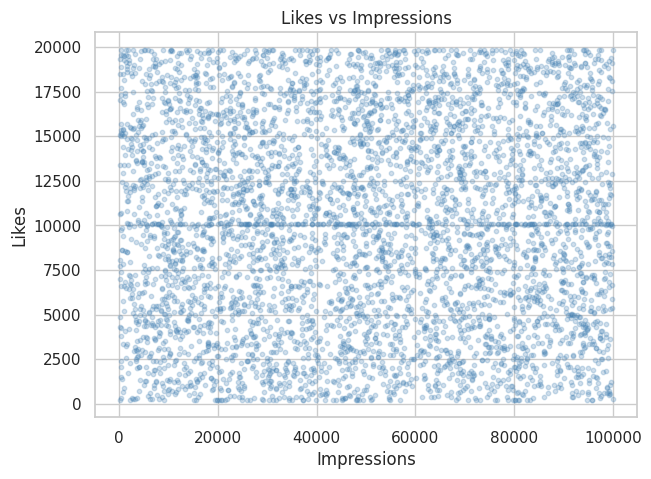

In [25]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df_clean["impression_count"], df_clean["likes"], alpha=0.25, s=10, color="steelblue")
ax.set(title="Likes vs Impressions", xlabel="Impressions", ylabel="Likes")
plt.show()

**Plot 1 – Scatter: a shapeless cloud **

---



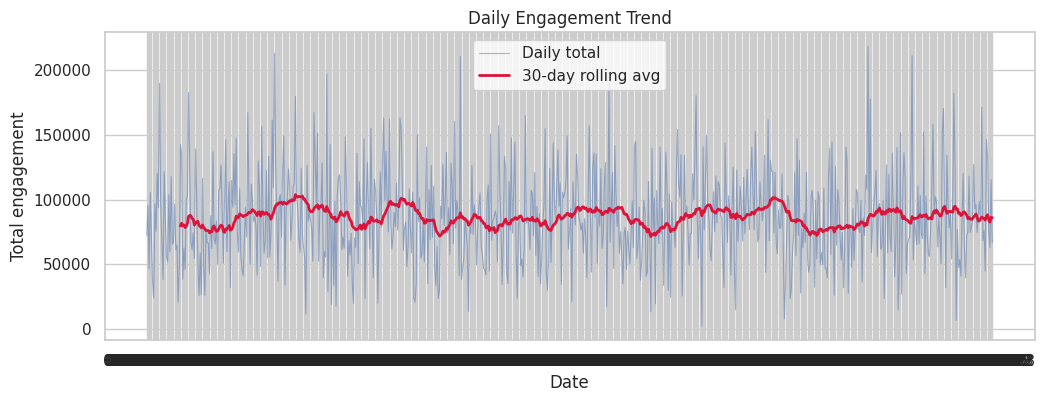

In [26]:
daily = df_clean.groupby("posted_at")["total_engagement"].sum()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily.values, lw=0.8, alpha=0.5, label="Daily total")
ax.plot(daily.rolling(30).mean(), color="crimson", lw=2, label="30-day rolling avg")
ax.set(title="Daily Engagement Trend", xlabel="Date", ylabel="Total engagement"); ax.legend()
plt.show()

**Plot 2 – Line: daily totals are noisy; the 30-day rolling average smooths them to show the underlying trend**

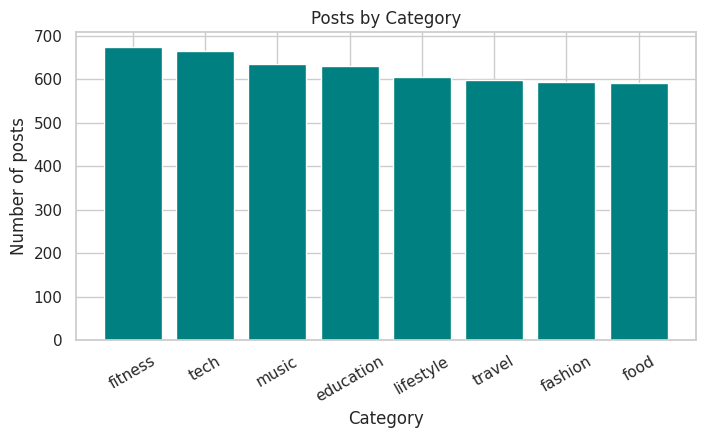

In [27]:
cat_counts = df_clean["post_category"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(cat_counts.index, cat_counts.values, color="teal")
ax.set(title="Posts by Category", xlabel="Category", ylabel="Number of posts"); plt.xticks(rotation=30)
plt.show()

**Plot 3 – Bar: posts are spread fairly evenly across categories **

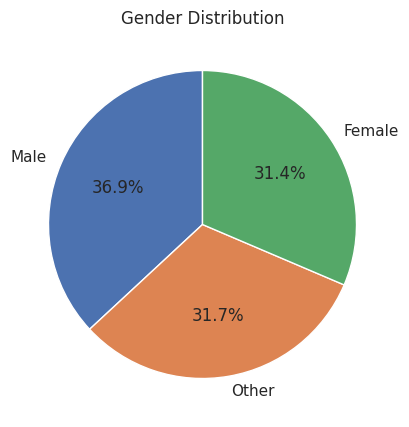

In [28]:
g = df_clean["gender"].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(g.values, labels=g.index.str.title(), autopct="%1.1f%%", startangle=90,
        colors=["#4c72b0", "#dd8452", "#55a868"])
plt.title("Gender Distribution"); plt.show()

**Plot 4 – Pie: gender split is close to one-third each.**

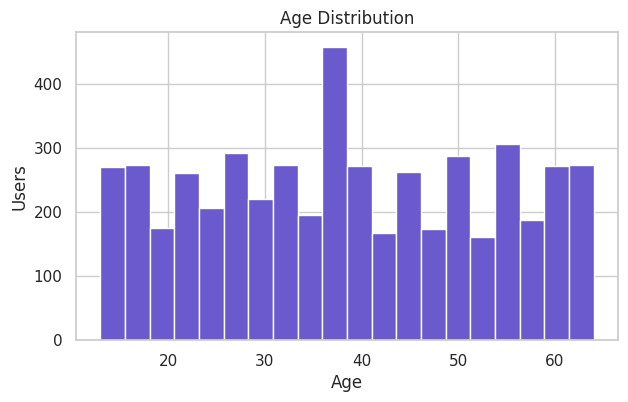

In [29]:
plt.figure(figsize=(7, 4))
plt.hist(df_clean["age"], bins=20, color="slateblue", edgecolor="white")
plt.title("Age Distribution"); plt.xlabel("Age"); plt.ylabel("Users"); plt.show()

**Plot 5 – Histogram: ages are roughly uniform from 13 to 64 – no dominant age band.**

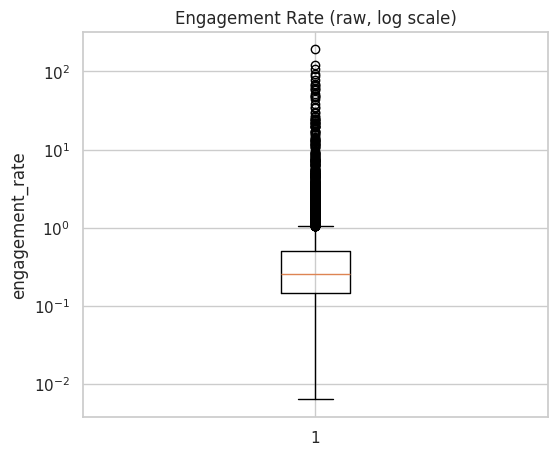

In [30]:
plt.figure(figsize=(6, 5))
plt.boxplot(df_clean["engagement_rate_raw"], vert=True, showfliers=True)
plt.yscale("log"); plt.title("Engagement Rate (raw, log scale)"); plt.ylabel("engagement_rate")
plt.show()

**Seaborn**

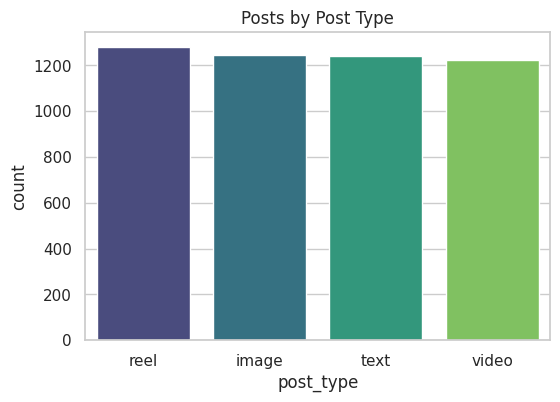

In [31]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x="post_type", order=df_clean.post_type.value_counts().index, palette="viridis")
plt.title("Posts by Post Type"); plt.show()

**Plot 7 – Count plot: reels, images, text and video each make up ~25 % of posts.**

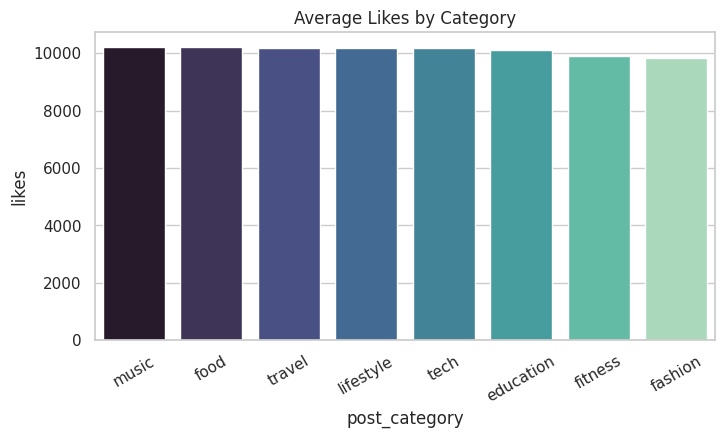

In [32]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df_clean, x="post_category", y="likes", estimator=np.mean, errorbar=None,
            order=df_clean.groupby("post_category")["likes"].mean().sort_values(ascending=False).index, palette="mako")
plt.title("Average Likes by Category"); plt.xticks(rotation=30); plt.show()

**Plot 8 – Bar plot: average likes are almost identical across categories, so category barely changes likes.**

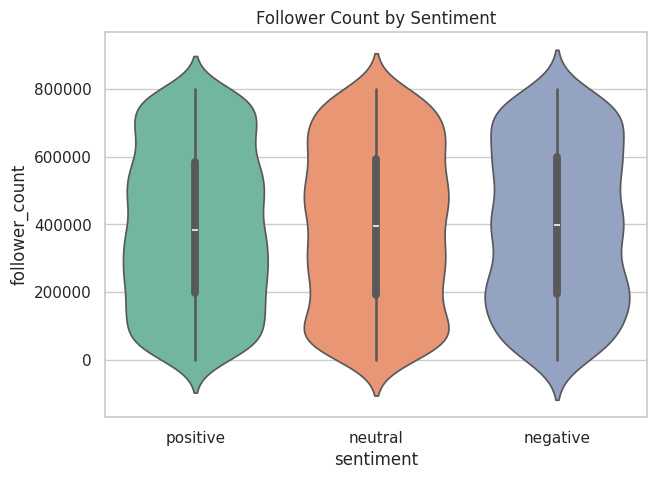

In [33]:
plt.figure(figsize=(7, 5))
sns.violinplot(data=df_clean, x="sentiment", y="follower_count", order=["positive", "neutral", "negative"], palette="Set2")
plt.title("Follower Count by Sentiment"); plt.show()

**Plot 9 – Violin: the three shapes are nearly identical → follower count is unrelated to sentiment.**

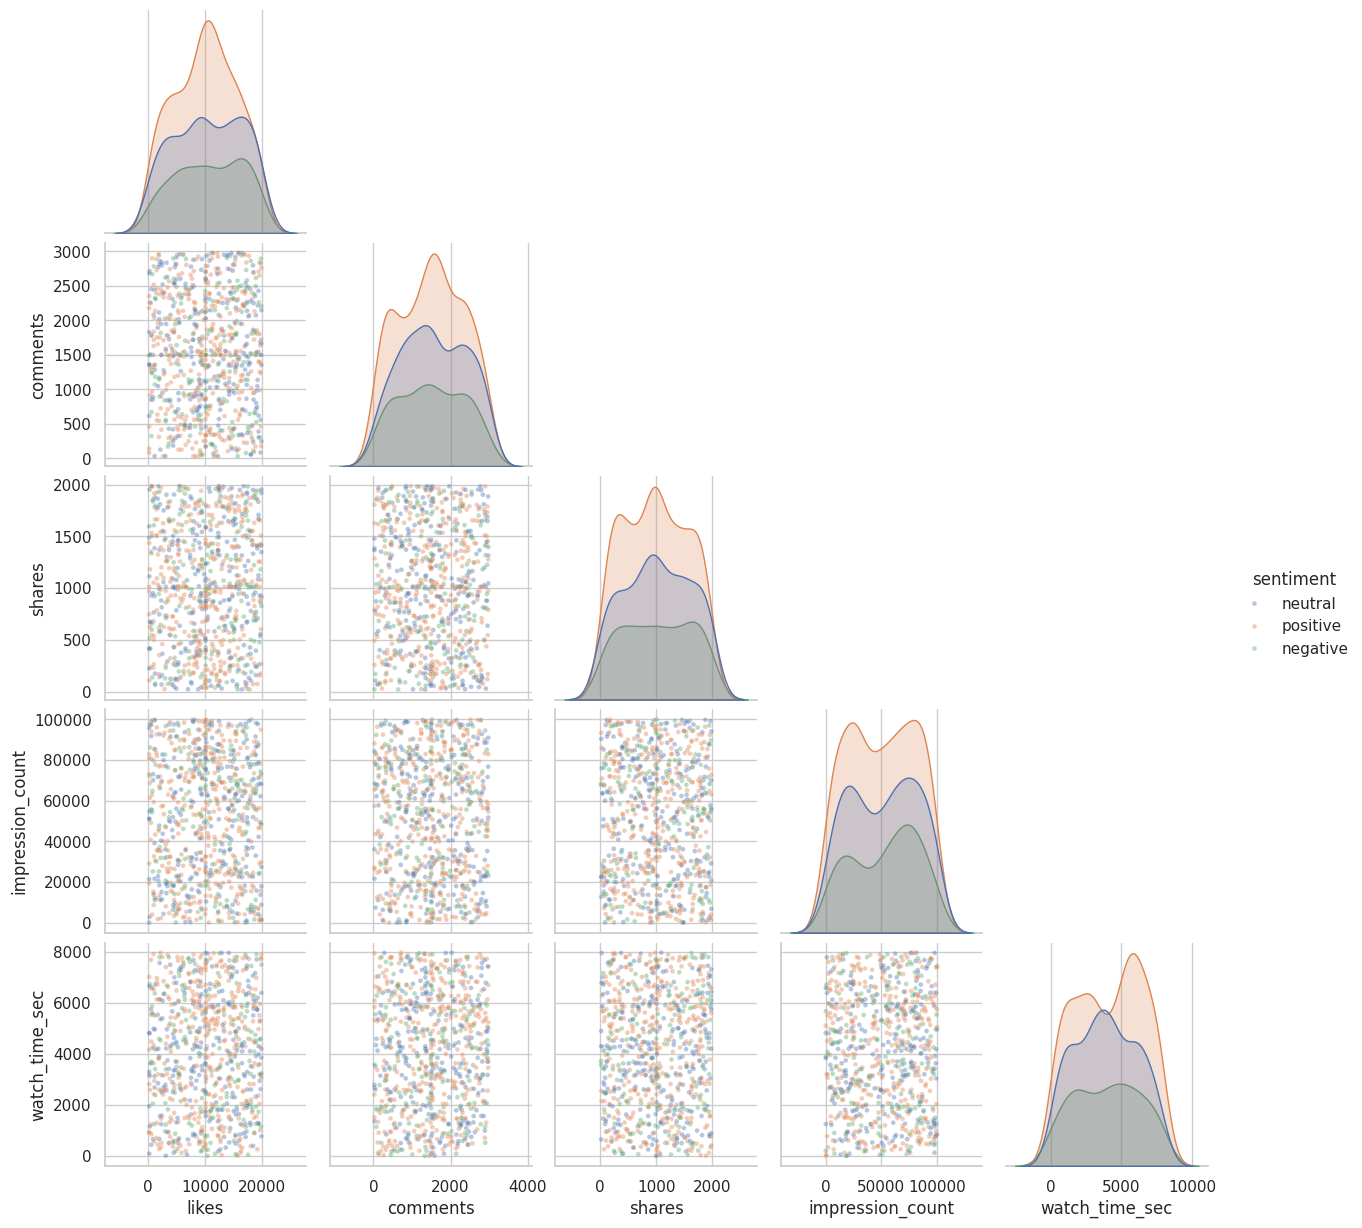

In [34]:
sns.pairplot(df_clean.sample(800, random_state=1),
             vars=["likes", "comments", "shares", "impression_count", "watch_time_sec"],
             hue="sentiment", plot_kws=dict(alpha=0.4, s=12), corner=True)
plt.show()

**Plot 10 – Pair plot : no clear linear pattern between any pair, which agrees with the correlation matrix.**

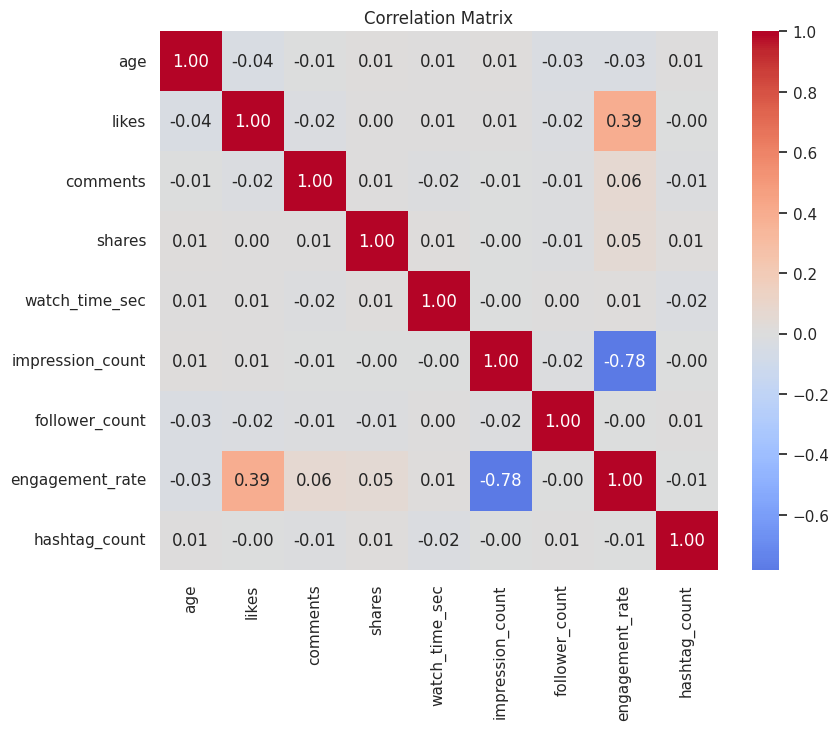

In [35]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix"); plt.show()

**Plot 11 – Heatmap: the only visible structure is the negative link between impressions and engagement rate**

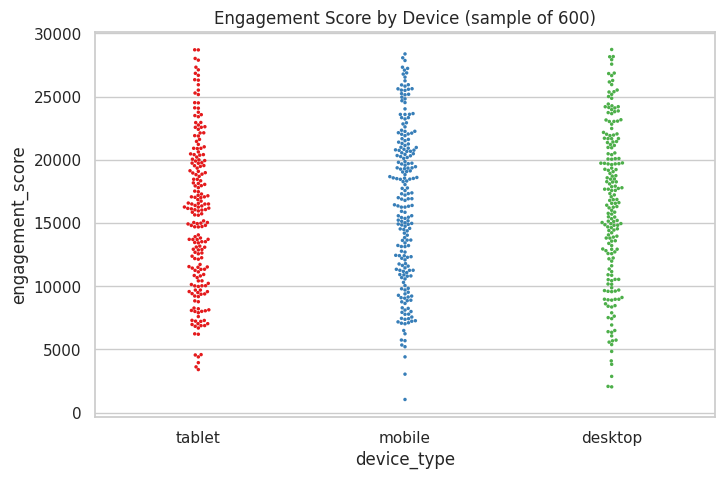

In [36]:
# Swarm plots get slow/crowded with thousands of points, so use a 600-row sample
samp = df_clean.sample(600, random_state=2)
plt.figure(figsize=(8, 5))
sns.swarmplot(data=samp, x="device_type", y="engagement_score", size=2.5, palette="Set1")
plt.title("Engagement Score by Device (sample of 600)"); plt.show()

**Plotly (interactive)**

In [37]:
monthly = df_clean.groupby("post_month")[["likes", "comments", "shares"]].sum().reset_index()
fig = px.line(monthly, x="post_month", y=["likes", "comments", "shares"], markers=True,
              title="Monthly Engagement Trend (hover / zoom / click legend)")
fig.update_layout(xaxis_title="Month", yaxis_title="Total")
fig.show()

KeyError: 'post_month'

In [38]:
cp = df_clean.groupby("country").agg(avg_rate=("engagement_rate", "mean"), avg_followers=("follower_count", "mean"),
                                     posts=("post_id", "count")).reset_index()
fig = px.scatter(cp, x="avg_followers", y="avg_rate", size="posts", color="country", text="country",
                 title="Country bubble chart: avg engagement rate vs avg followers (bubble = posts)")
fig.update_traces(textposition="top center"); fig.show()

In [39]:
fig = px.bar(df_clean.groupby(["post_type", "sentiment"])["engagement_score"].mean().reset_index(),
             x="post_type", y="engagement_score", color="sentiment", barmode="group",
             title="Avg engagement score by post type and sentiment")
fig.show()

**Final Insights**

**The code below calculates every number used in the written findings**  

In [40]:
def show(title, s): print(f"\n### {title}"); display(s)

# --- Content performance
show("Post type: engagement metrics", df_clean.groupby("post_type").agg(
     mean_rate=("engagement_rate","mean"), median_rate=("engagement_rate","median"),
     avg_score=("engagement_score","mean"), avg_interactions=("total_engagement","mean")).round(4).sort_values("avg_score", ascending=False))
show("Post category: engagement metrics", df_clean.groupby("post_category").agg(
     mean_rate=("engagement_rate","mean"), median_rate=("engagement_rate","median"),
     avg_score=("engagement_score","mean"), avg_interactions=("total_engagement","mean")).round(4).sort_values("avg_score", ascending=False))
show("Country: engagement rate", df_clean.groupby("country").agg(
     mean_rate=("engagement_rate","mean"), median_rate=("engagement_rate","median"),
     avg_score=("engagement_score","mean")).round(4).sort_values("mean_rate", ascending=False))


### Post type: engagement metrics


,mean_rate,median_rate,avg_score,avg_interactions
post_type,,,,
image,0.3729,0.2641,16209.0458,12647.0699
video,0.3760,0.2470,16140.3908,12665.2756
text,0.3762,0.2543,16134.6380,12610.6299
reel,0.3600,0.2476,15992.4114,12523.3966



### Post category: engagement metrics


,mean_rate,median_rate,avg_score,avg_interactions
post_category,,,,
music,0.3798,0.2561,16406.1672,12801.7145
food,0.3570,0.2532,16233.0541,12720.3412
tech,0.3696,0.2508,16210.8707,12686.6361
lifestyle,0.3703,0.2484,16102.5695,12648.1192
travel,0.3655,0.2514,16073.0417,12651.7045
fitness,0.3833,0.2485,16035.2389,12452.9792
education,0.3782,0.2754,16018.0556,12571.6571
fashion,0.3631,0.2590,15853.0320,12353.1906



### Country: engagement rate


,mean_rate,median_rate,avg_score
country,,,
Australia,0.3939,0.2696,16348.3061
Japan,0.3846,0.2617,16028.3602
UAE,0.3832,0.2732,16286.2470
Germany,0.3793,0.2680,16104.3027
Canada,0.3780,0.2641,16146.4219
Brazil,0.3756,0.2483,15895.1746
France,0.3673,0.2426,16485.8548
USA,0.3589,0.2420,16023.4212
UK,0.3540,0.2411,15792.0020


In [41]:
# --- User trends
show("Age group", df_clean.groupby("age_group").agg(posts=("post_id","count"), mean_rate=("engagement_rate","mean"),
     median_rate=("engagement_rate","median"), avg_score=("engagement_score","mean")).round(4))
print("Correlation age vs engagement_score:", df_clean.age.corr(df_clean.engagement_score).round(3))
print("Correlation age vs engagement_rate :", df_clean.age.corr(df_clean.engagement_rate).round(3))
show("Verified vs not verified", df_clean.groupby("is_verified").agg(posts=("post_id","count"), mean_rate=("engagement_rate","mean"),
     median_rate=("engagement_rate","median"), avg_likes=("likes","mean"), avg_score=("engagement_score","mean"),
     avg_followers=("follower_count","mean"), avg_impr=("impression_count","mean")).round(4))

KeyError: 'age_group'

In [42]:
# --- Behavioural insights
# posted_at has DATE only, so true 'time of day' cannot be measured.
# We use day-of-week and month as the closest available time dimensions.
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
show("Avg impressions by day of week", df_clean.groupby("post_dow")["impression_count"].mean().reindex(order).round(0))
show("Avg impressions by month (top 5)", df_clean.groupby("post_month")["impression_count"].mean().sort_values(ascending=False).head(5).round(0))
show("Device vs watch time & impressions", df_clean.groupby("device_type").agg(avg_watch=("watch_time_sec","mean"),
     median_watch=("watch_time_sec","median"), avg_impr=("impression_count","mean")).round(1).sort_values("avg_watch", ascending=False))

KeyError: 'post_dow'

In [43]:
# --- Sentiment
show("Sentiment performance", df_clean.groupby("sentiment").agg(posts=("post_id","count"), mean_rate=("engagement_rate","mean"),
     median_rate=("engagement_rate","median"), avg_likes=("likes","mean"), avg_comments=("comments","mean"),
     avg_shares=("shares","mean"), avg_score=("engagement_score","mean"), avg_watch=("watch_time_sec","mean"),
     avg_impr=("impression_count","mean")).round(4).sort_values("avg_score", ascending=False))
show("Sentiment share (%)", (df_clean.sentiment.value_counts(normalize=True)*100).round(1))


### Sentiment performance


,posts,mean_rate,median_rate,avg_likes,avg_comments,avg_shares,avg_score,avg_watch,avg_impr
sentiment,,,,,,,,,
negative,958,0.3752,0.2555,10207.7610,1514.5741,1006.1472,16255.3507,4055.6493,50192.5042
positive,2358,0.3703,0.2553,10158.0034,1482.0925,1002.1802,16128.7290,3983.3321,50011.5305
neutral,1675,0.3701,0.2510,9975.3833,1521.3994,1002.1415,16024.6066,4036.6913,49962.1845



### Sentiment share (%)


,proportion
sentiment,
positive,47.2
neutral,33.6
negative,19.2


In [44]:

from scipy import stats as st
for col, grp in [("engagement_score", "post_type"), ("engagement_score", "sentiment"), ("watch_time_sec", "device_type")]:
    groups = [g[col].values for _, g in df_clean.groupby(grp)]
    F, p = st.f_oneway(*groups)
    print(f"ANOVA {col} ~ {grp}:  F = {F:.2f},  p = {p:.3f}  ->", "significant" if p < 0.05 else "NOT significant")
t, p = st.ttest_ind(df_clean[df_clean.is_verified].engagement_score, df_clean[~df_clean.is_verified].engagement_score)
print(f"t-test verified vs not (engagement_score): t = {t:.2f}, p = {p:.3f} ->", "significant" if p < 0.05 else "NOT significant")

ANOVA engagement_score ~ post_type:  F = 0.28,  p = 0.843  -> NOT significant
ANOVA engagement_score ~ sentiment:  F = 0.43,  p = 0.649  -> NOT significant
ANOVA watch_time_sec ~ device_type:  F = 1.25,  p = 0.286  -> NOT significant
t-test verified vs not (engagement_score): t = -1.31, p = 0.189 -> NOT significant
